# Freight rate assessment — Stage 1 EDA

Run the cells from top to bottom. This notebook reuses the tested analysis in `stage1_eda.py`, prints its diagnostics in notebook output, saves charts to `outputs/eda/`, and displays those charts inline.

Select the project's Python environment as the notebook kernel. If dependencies are not installed yet, run this in PowerShell from the project folder:

```powershell
.\env\Scripts\python.exe -m pip install -r requirements.txt
```

Input CSVs are expected next to this notebook.

## Load data and workflow

In [1]:
from pathlib import Path
import runpy

workflow = runpy.run_path(str(Path.cwd() / "stage1_eda.py"))
train = workflow["pd"].read_csv(workflow["TRAIN_PATH"])
validation = workflow["pd"].read_csv(workflow["VALIDATION_PATH"])
train["date"] = workflow["pd"].to_datetime(train["date"], errors="coerce")
validation["date"] = workflow["pd"].to_datetime(validation["date"], errors="coerce")
print("Train:", train.shape, "Validation:", validation.shape)

Train: (48000, 14) Validation: (12000, 13)


## Overview, missingness, duplicates, and domain checks

In [2]:
workflow["inspect_dataset"]("train", train)
workflow["inspect_dataset"]("validation", validation)


=== TRAIN OVERVIEW ===
Shape: (48000, 14)
Date range: 2025-01-01 00:00:00 to 2025-10-31 00:00:00
Dtypes:
load_id                 object
pickup                  object
delivery                object
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment               object
weight                 float64
date            datetime64[ns]
market_index           float64
quote_signal           float64
posted_rate            float64
Missing values:
weight          300
market_index    374

Duplicate and domain checks:
Exact duplicate rows: 0
Duplicate load IDs: 0
Pickup equals delivery: 0
distance: negative=0, zero=0, missing=0
weight: negative=292, zero=0, missing=300
market_index: negative=0, zero=0, missing=374
quote_signal: negative=0, zero=0, missing=0
posted_rate: negative=0, zero=0, missing=0
Unique pickup cities: 64
Unique delivery cities: 64
Equipment counts:
equipment
Dry Van

## Geography and posted-rate analysis

In [3]:
workflow["inspect_geography"](train)
workflow["inspect_target"](train)


=== GEOGRAPHY ===
Distance/haversine correlation: 0.9995349596237094
Absolute distance error quantiles: {0.5: 144.22, 0.9: 318.69, 0.95: 364.74, 0.99: 440.08, 1.0: 581.69}
Distance/haversine ratio quantiles: {0.05: 1.143, 0.25: 1.165, 0.5: 1.182, 0.75: 1.205, 0.95: 1.273}
Rows with absolute distance error > 25 miles: 47800 / 48000
Cities with multiple coordinate pairs: 0 / 64
Pickup cities with multiple coordinate pairs: 0 / 64
Delivery cities with multiple coordinate pairs: 0 / 64

=== POSTED RATE ===
{'count': 48000.0, 'mean': 2373.98, 'std': 1486.49, 'min': 57.22, '1%': 327.17, '5%': 599.74, '25%': 1251.55, '50%': 2030.76, '75%': 3330.75, '95%': 4953.77, '99%': 5972.83, 'max': 25533.0}
Skew: 1.902
log1p skew: -0.489
IQR outliers: 260 (upper fence: 6449.54)
Rate per mile summary:
{'count': 48000.0, 'mean': 2.215, 'std': 0.584, 'min': 0.334, '1%': 1.674, '5%': 1.808, '50%': 2.145, '95%': 2.736, '99%': 3.177, 'max': 14.125}
Rate per mile by equipment:
           count   mean  median  

## Weekly/monthly trends, market signals, and train-validation drift

In [4]:
monthly, smd_values = workflow["inspect_time_and_drift"](train, validation)


=== WEEKLY TRENDS ===
            rows  mean_rate  mean_rate_per_mile  market_index  quote_signal
week                                                                       
2024-12-30   779   2223.762               2.059         0.910         2.058
2025-01-06  1151   2215.868               2.106         0.903         2.067
2025-01-13  1092   2296.886               2.129         0.918         2.067
2025-01-20  1120   2243.694               2.082         0.937         2.069
2025-10-06  1091   2368.144               2.242         0.970         1.941
2025-10-13  1102   2368.271               2.235         0.955         1.941
2025-10-20  1071   2359.432               2.228         0.944         1.946
2025-10-27   796   2380.062               2.244         0.969         1.930

=== MONTHLY TRENDS ===
            rows  mean_rate  mean_rate_per_mile  market_index  quote_signal
month                                                                      
2025-01-01  4918   2255.967              

## Save and display plots


=== SAVED PLOTS ===
outputs\eda\distance_vs_haversine.png
outputs\eda\monthly_rate_trends.png
outputs\eda\numeric_feature_drift.png
outputs\eda\posted_rate_distribution.png
outputs\eda\rate_per_mile_by_equipment.png
outputs\eda\rate_vs_distance_weight.png
outputs\eda\weekly_market_quote_trends.png
distance_vs_haversine.png


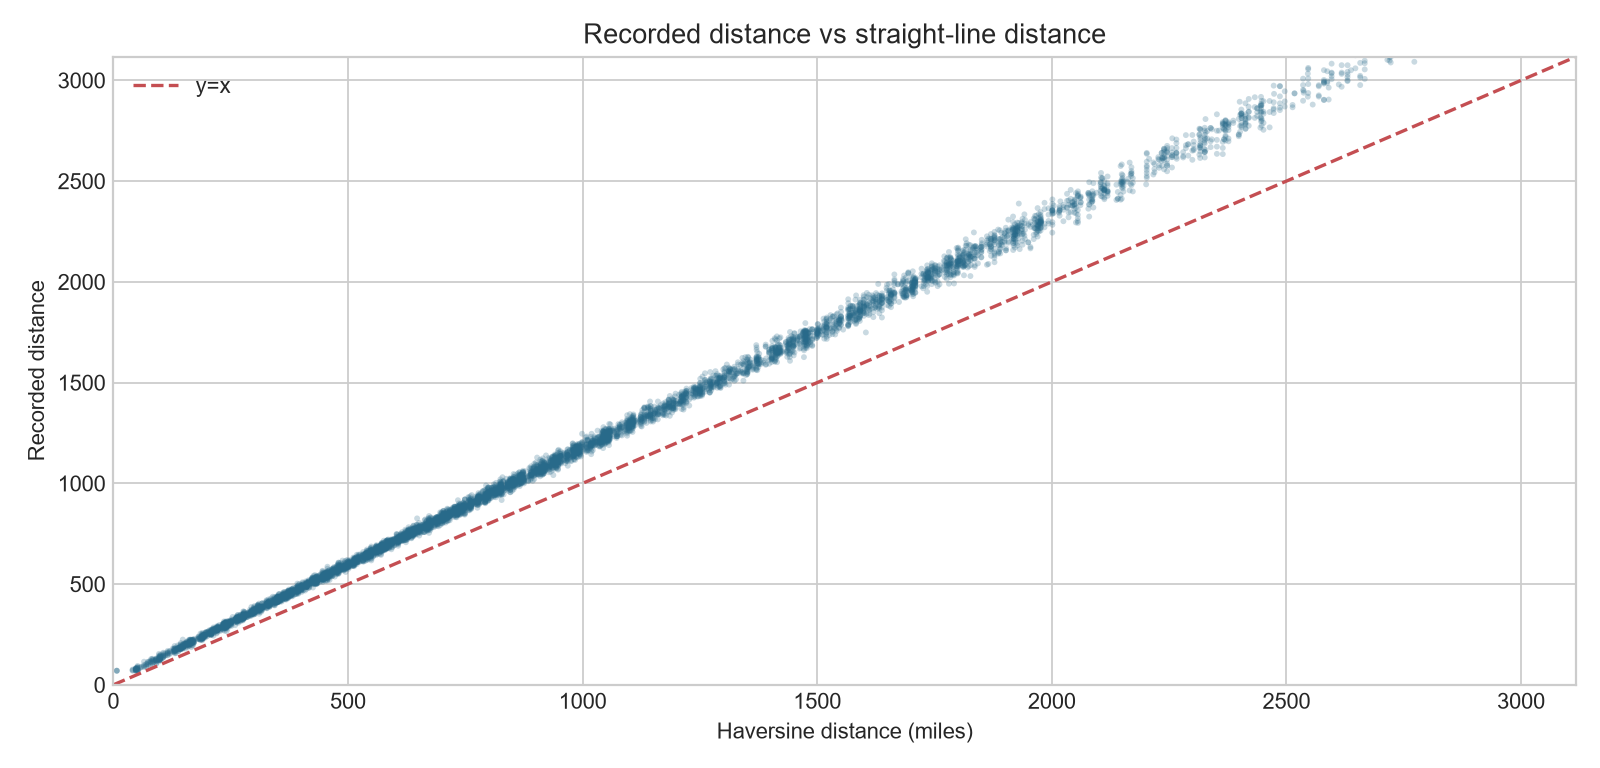

monthly_rate_trends.png


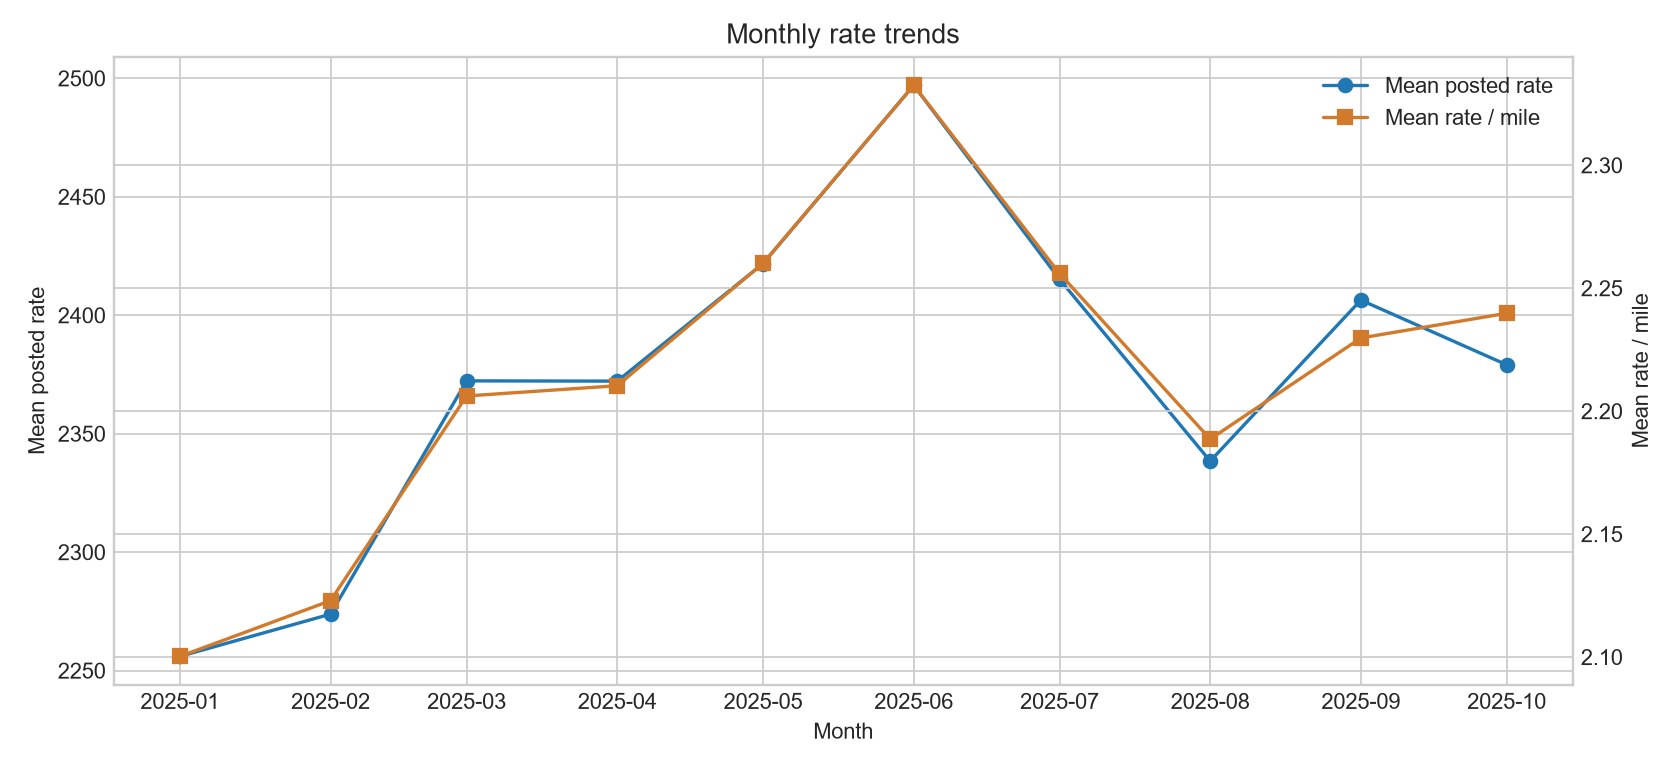

numeric_feature_drift.png


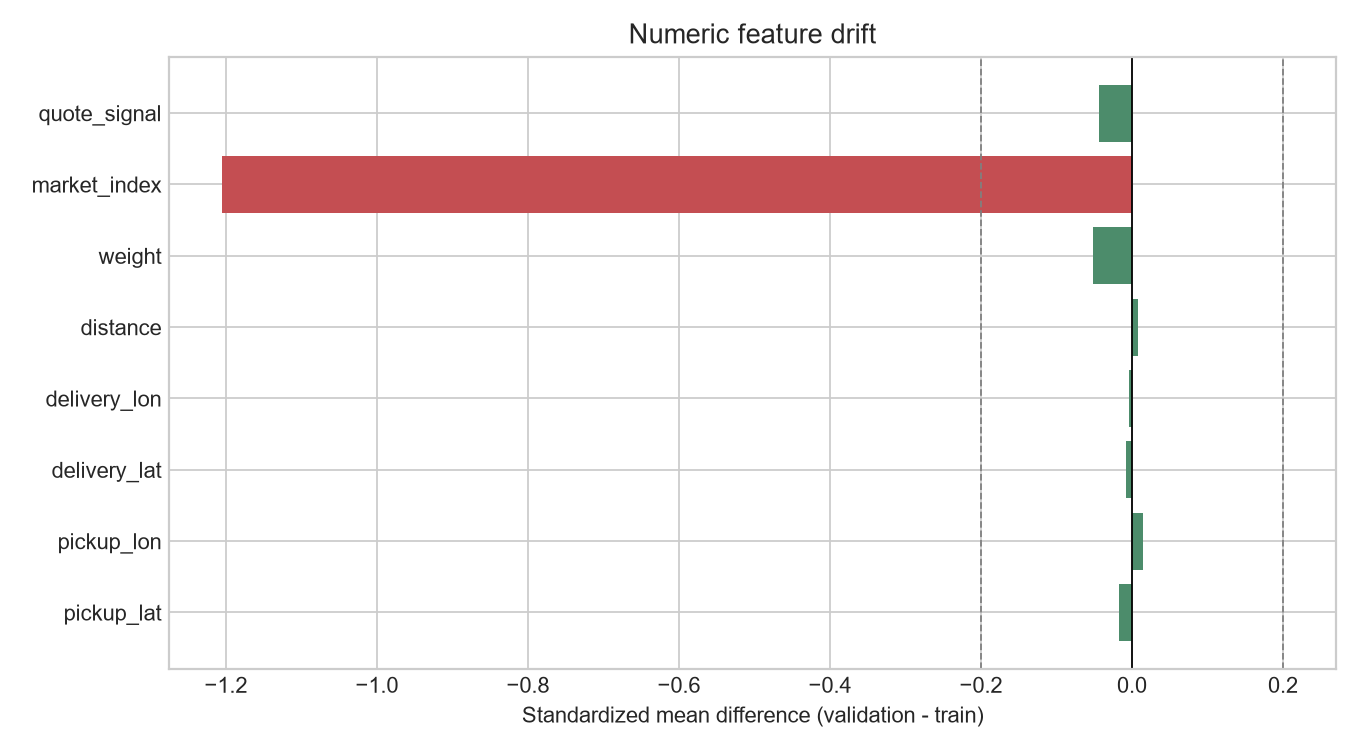

posted_rate_distribution.png


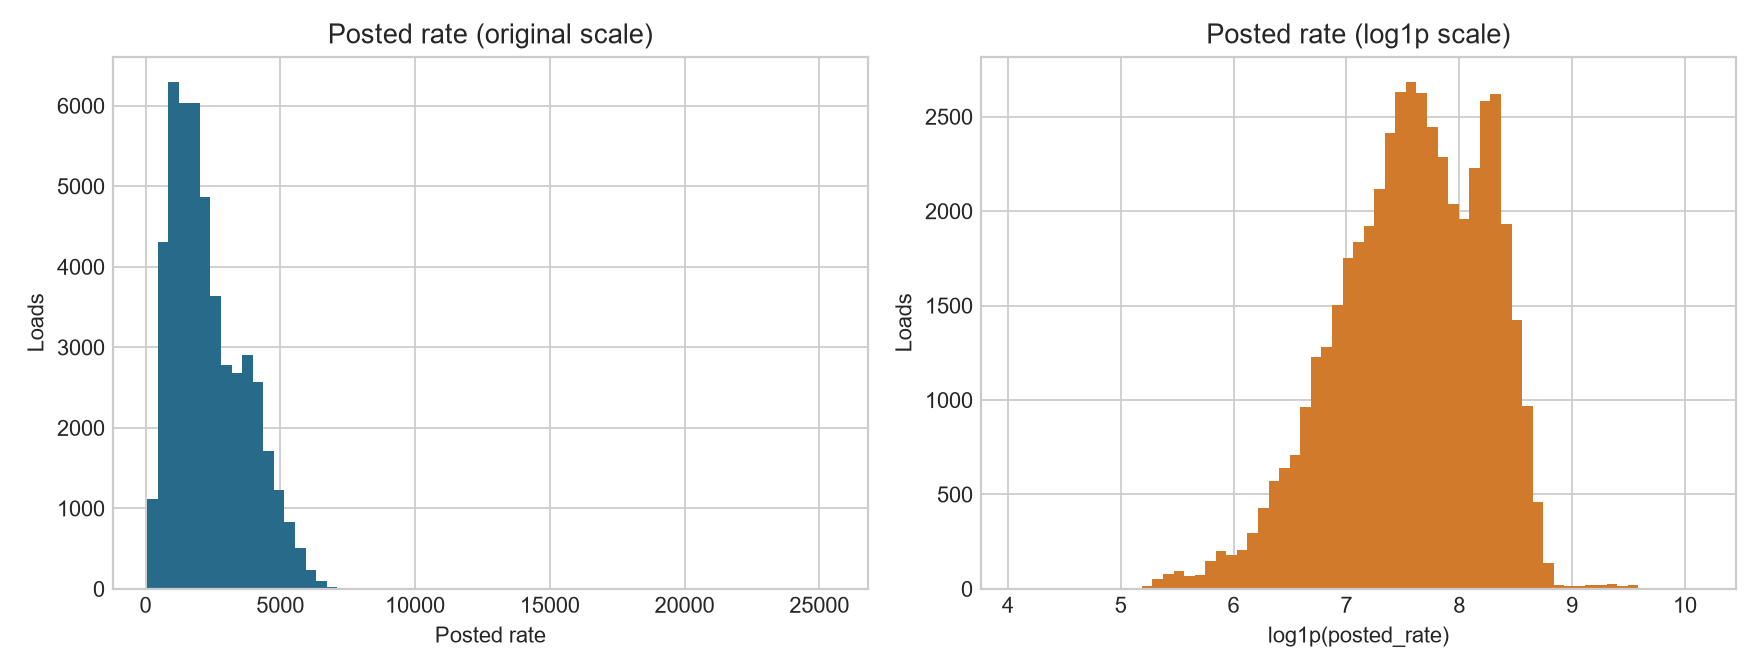

rate_per_mile_by_equipment.png


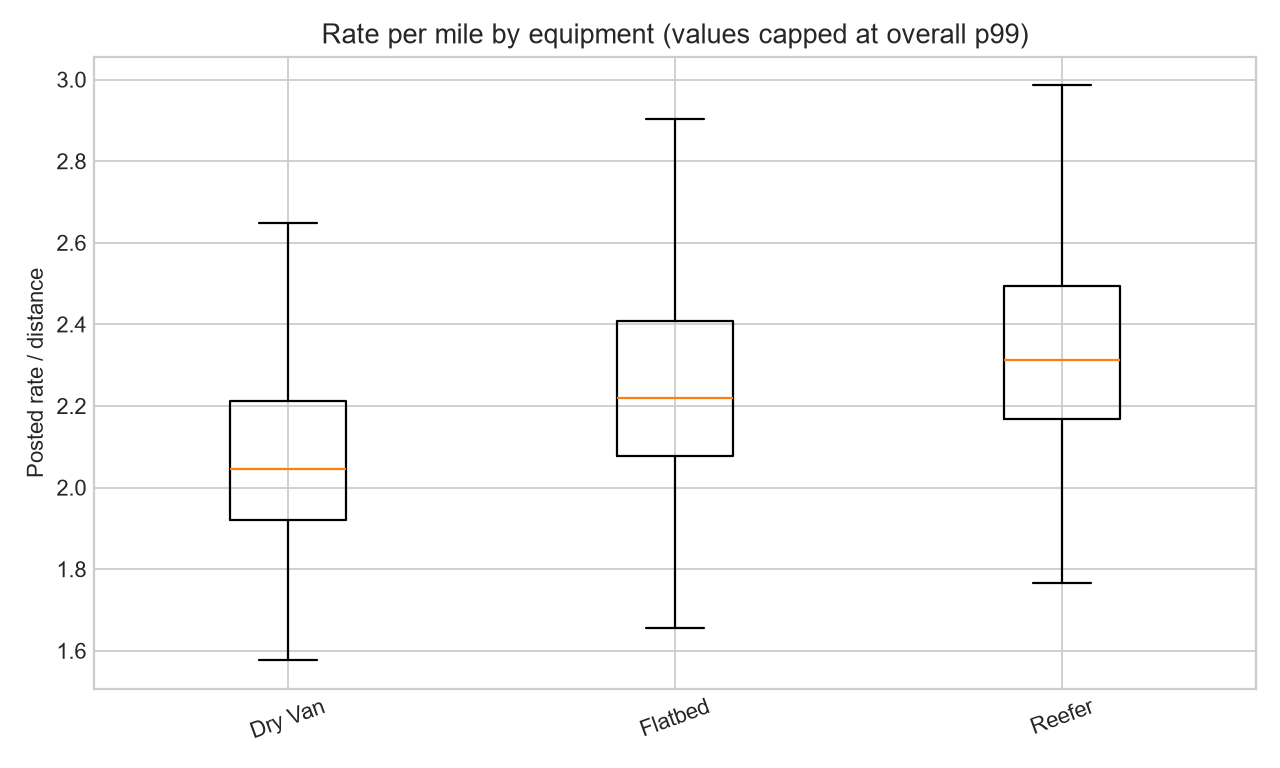

rate_vs_distance_weight.png


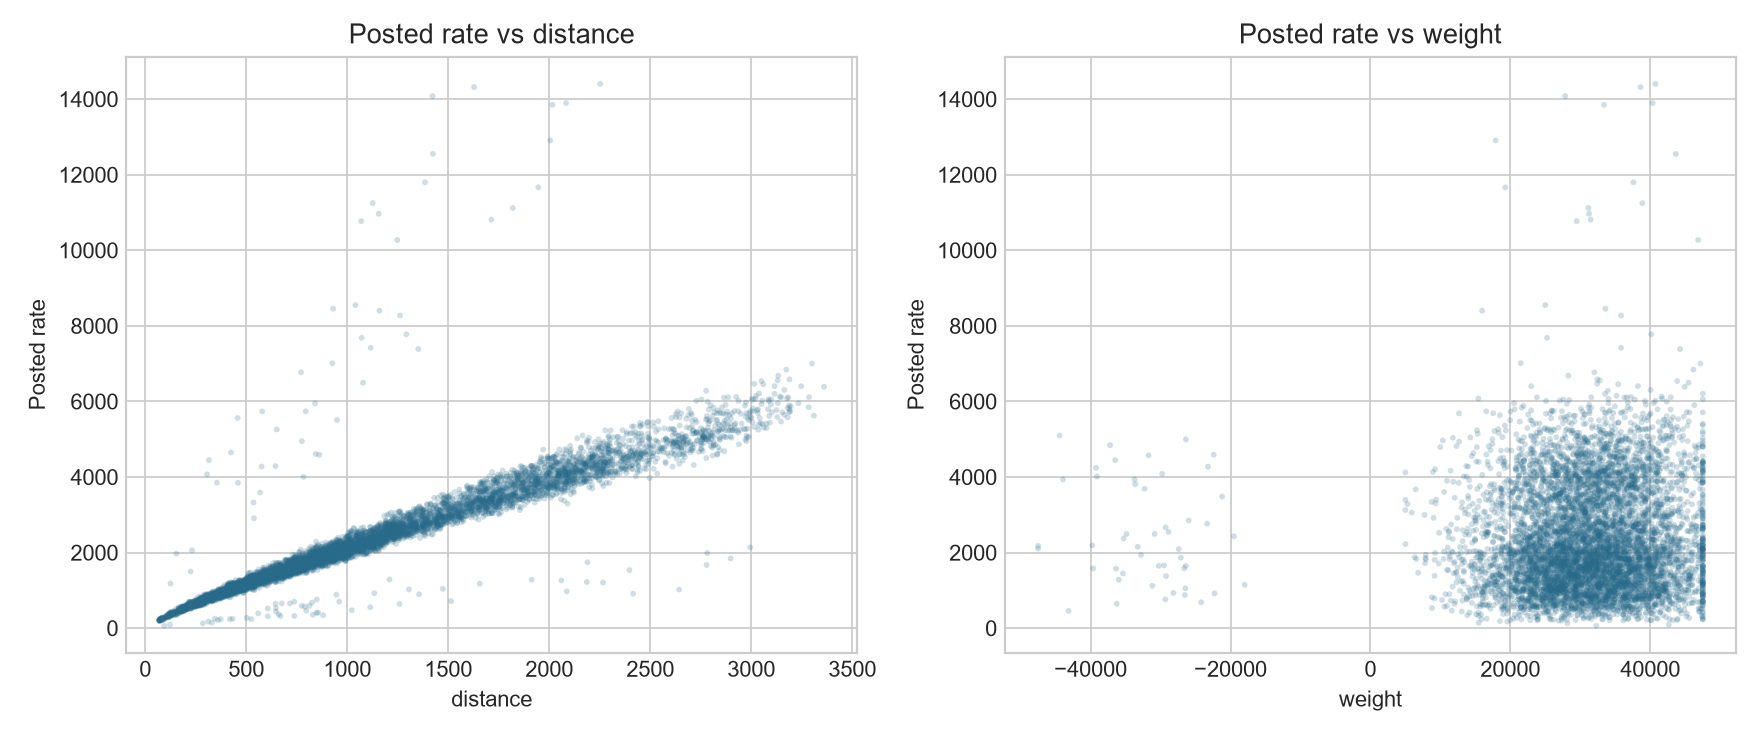

weekly_market_quote_trends.png


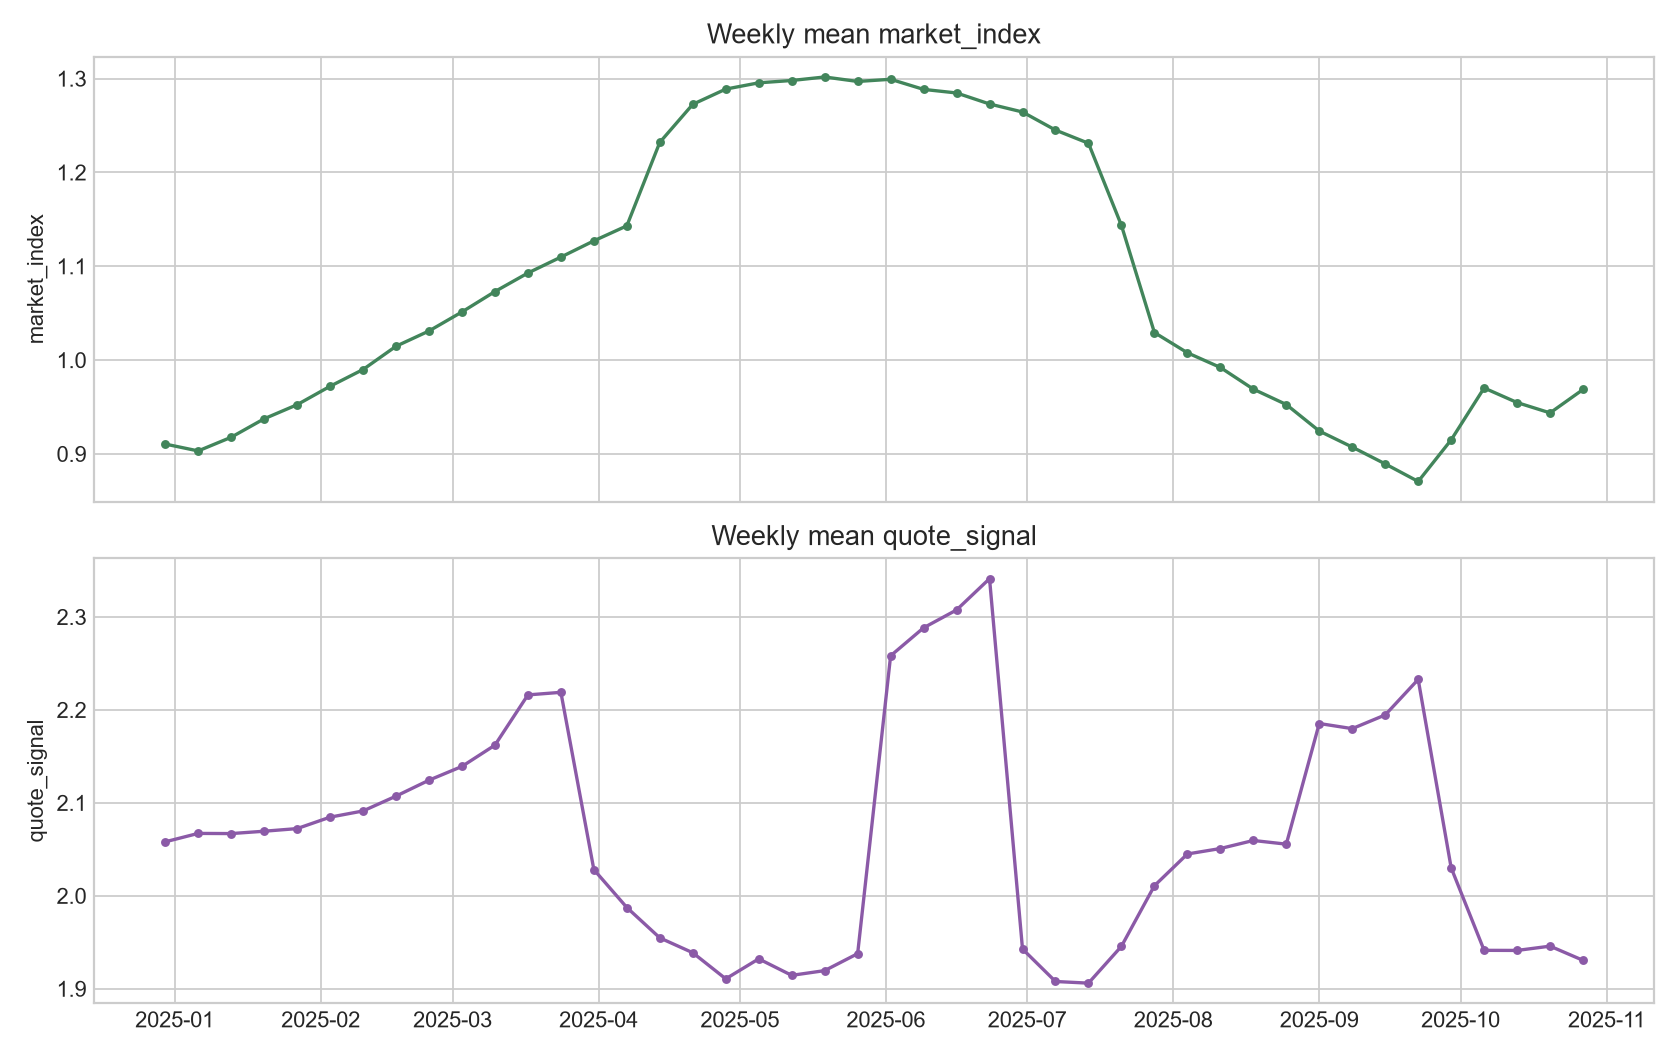

In [5]:
from IPython.display import Image, display

workflow["save_plots"](train, validation, monthly, smd_values)
for plot_path in sorted(workflow["OUTPUT_DIR"].glob("*.png")):
    print(plot_path.name)
    display(Image(filename=str(plot_path)))